In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

import warnings
warnings.filterwarnings('ignore')

pd.set_option("display.max_columns", None) # do not hide any columns every time we run it



### 1. Data Loading & Initial Inspection

In [3]:
from sklearn.datasets import load_breast_cancer

dataset = load_breast_cancer(as_frame=True)

x = dataset.data
y = dataset.target

print("Dataset loaded successfully!")
print("Features shape:", x.shape)
print("Target shape:", y.shape)

Dataset loaded successfully!
Features shape: (569, 30)
Target shape: (569,)


In [4]:
df = x.copy();
df['target'] = y;

print("Dataframe created successfully!");
print("=" * 50);
print("Dataframe shape:", df.shape);

Dataframe created successfully!
Dataframe shape: (569, 31)


In [5]:
print("=" * 50);
print("Dataframe head:");
print(df.head());

Dataframe head:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  radius error  texture error  perimeter error  \
0

In [6]:
print("Dataframe info:");
print(df.info());
print("=" * 50);

Dataframe info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness

In [7]:
print("Dataframe description:");
print(df.describe());
print("=" * 50);

Dataframe description:
       mean radius  mean texture  mean perimeter    mean area  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
std           0.014064          0.052813        0.079720             0.038803   
min           0.052630          0.019380        0.000000           

In [8]:
print("=" * 50);

print("Checking for duplicates:");
print(df.duplicated().sum());

print("=" * 50);

print("Checking for missing values:");
print(df.isna().sum());

print("=" * 50);

Checking for duplicates:
0
Checking for missing values:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64


In [19]:
print(df.select_dtypes(include=[np.number]))

     mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0          17.99         10.38          122.80     1001.0          0.11840   
1          20.57         17.77          132.90     1326.0          0.08474   
2          19.69         21.25          130.00     1203.0          0.10960   
3          11.42         20.38           77.58      386.1          0.14250   
4          20.29         14.34          135.10     1297.0          0.10030   
..           ...           ...             ...        ...              ...   
564        21.56         22.39          142.00     1479.0          0.11100   
565        20.13         28.25          131.20     1261.0          0.09780   
566        16.60         28.08          108.30      858.1          0.08455   
567        20.60         29.33          140.10     1265.0          0.11780   
568         7.76         24.54           47.92      181.0          0.05263   

     mean compactness  mean concavity  mean concave points  mea

In [10]:
missing_raw = df.isna().sum().to_frame("Missing_Count")
missing_raw["Missing_%"] = (df.isna().mean() * 100).round(2)

missing_raw.sort_values("Missing_%", ascending=False)


,Missing_Count,Missing_%
mean radius,0,0.0
mean texture,0,0.0
mean perimeter,0,0.0
mean area,0,0.0
mean smoothness,0,0.0
mean compactness,0,0.0
mean concavity,0,0.0
mean concave points,0,0.0
mean symmetry,0,0.0
mean fractal dimension,0,0.0


## 2. Basic Data Cleaning

The dataset is already clean and ready for the exploration stage.

The following cleaning steps were considered:

- Checking for exact duplicate rows.
- Checking for missing values.

The `DateTime` step is skipped because this dataset does not contain any `DateTime` or date-related features.

## 3. Exploratory Data Analysis (EDA)

In [13]:
print("Count:")
print(df["target"].value_counts())

print("\nPercent:")
print((df["target"].value_counts(normalize=True) * 100).round(2))

Count:
target
1    357
0    212
Name: count, dtype: int64

Percent:
target
1    62.74
0    37.26
Name: proportion, dtype: float64


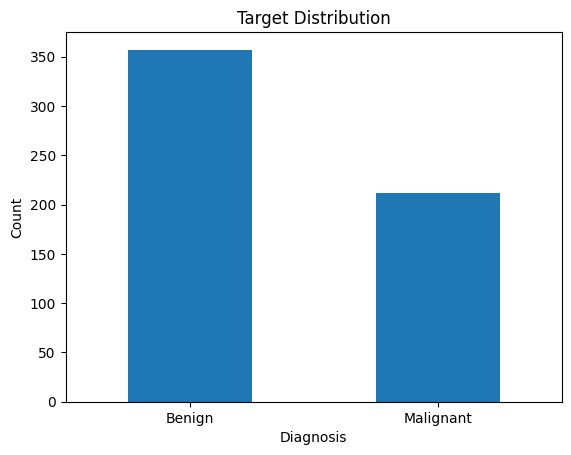

In [18]:
target_mapping = {
    0: "Malignant",
    1: "Benign"
}

target_counts = df["target"].map(target_mapping).value_counts()

target_counts.plot(kind="bar")

plt.title("Target Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.xticks(rotation=0)

plt.show()

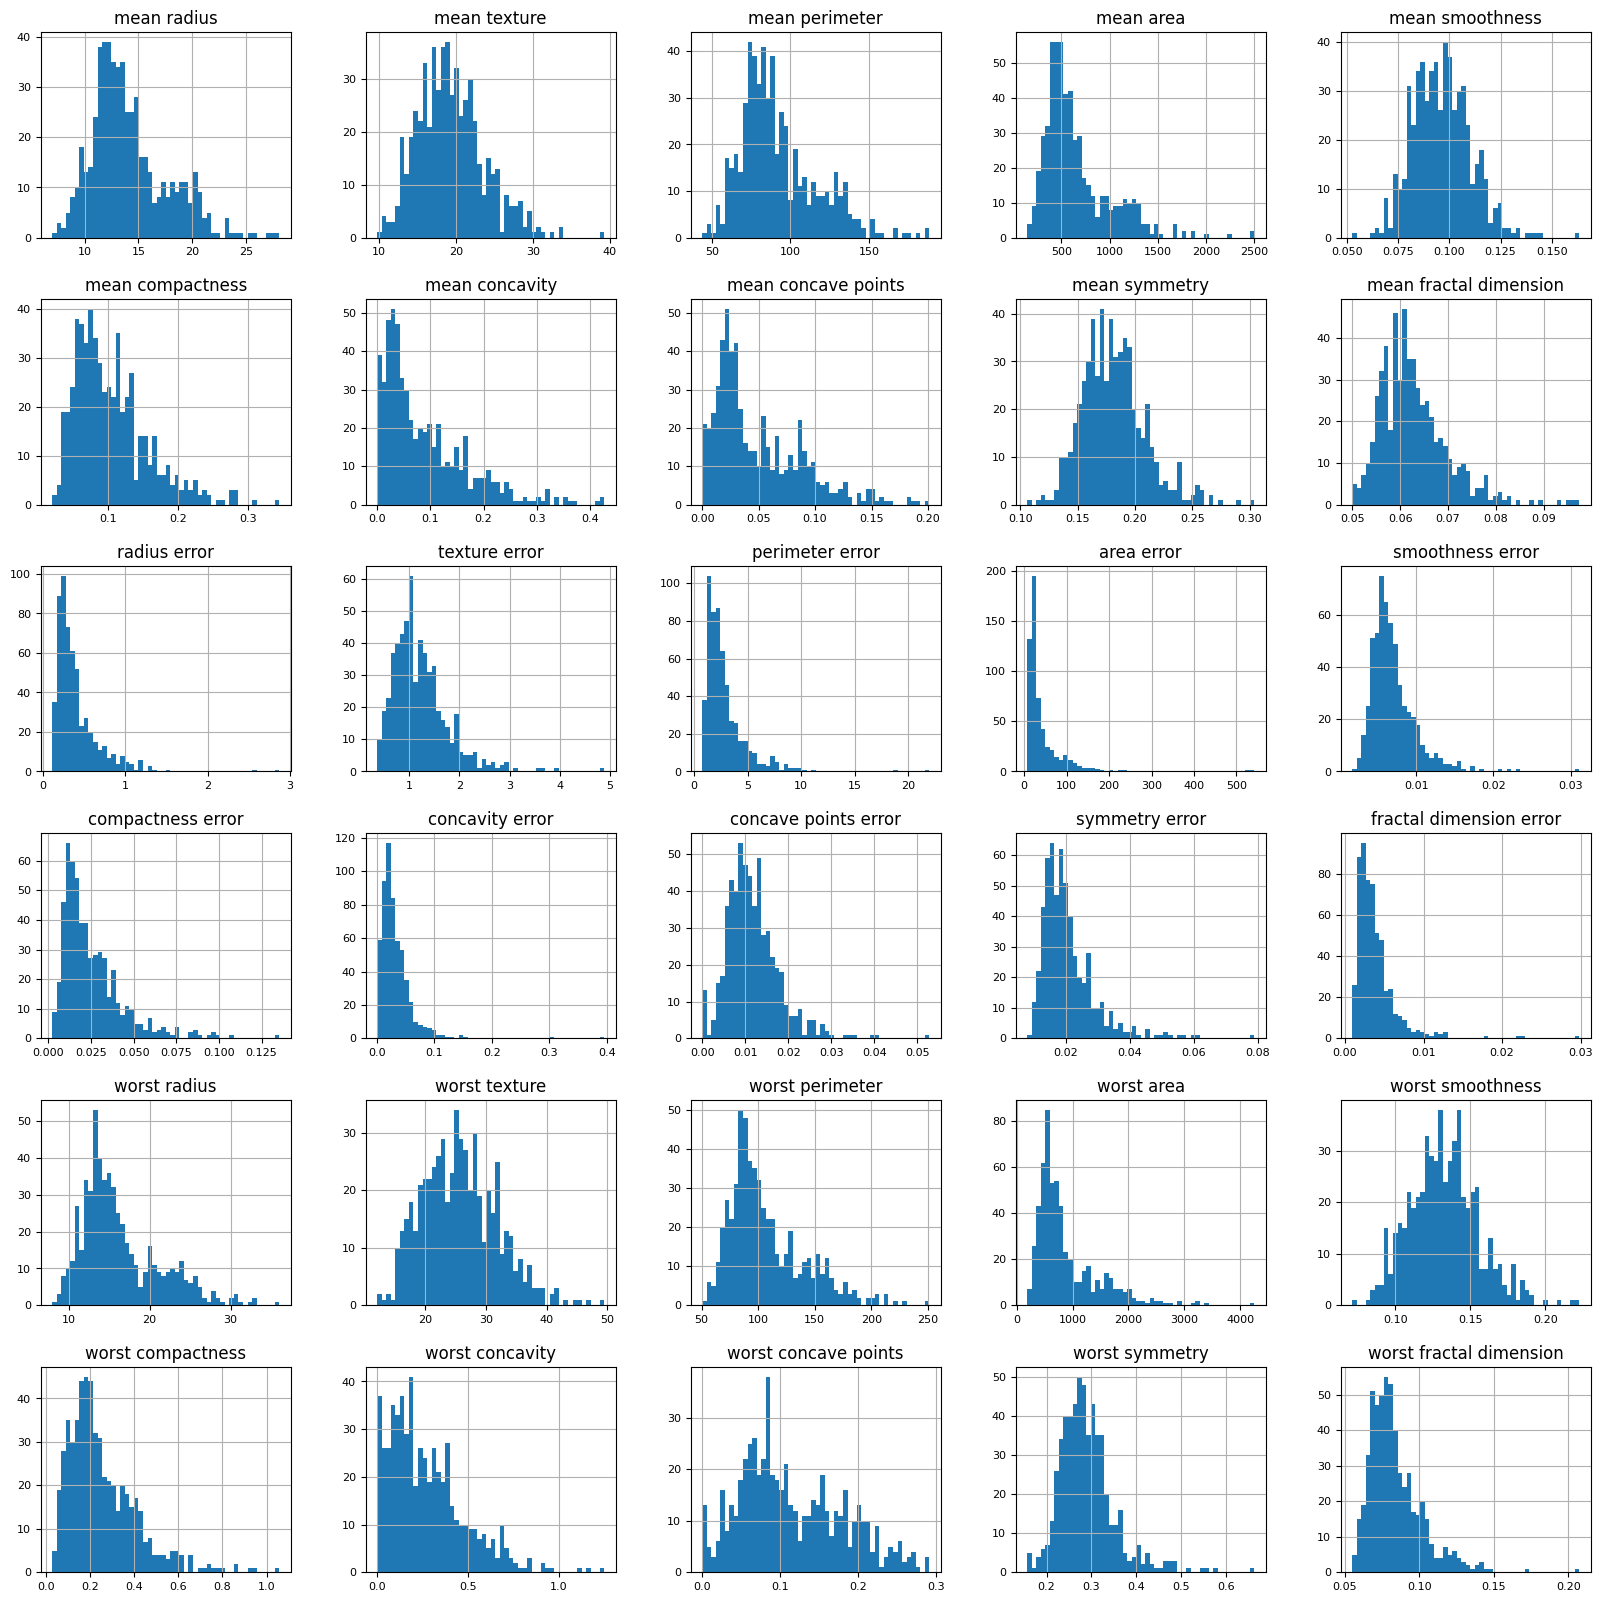

In [28]:
numeric_cols = df.select_dtypes(include=[np.number]);
numeric_cols = numeric_cols.drop(columns=["target"]);
numeric_cols.hist(figsize=(20, 20), bins=50, xlabelsize=8, ylabelsize=8);

In [29]:
numeric_cols.skew().round(3).sort_values(key=abs, ascending=False)

area error                 5.447
concavity error            5.110
fractal dimension error    3.924
perimeter error            3.444
radius error               3.089
smoothness error           2.314
symmetry error             2.195
compactness error          1.902
worst area                 1.859
worst fractal dimension    1.663
mean area                  1.646
texture error              1.646
worst compactness          1.474
concave points error       1.445
worst symmetry             1.434
mean concavity             1.401
mean fractal dimension     1.304
mean compactness           1.190
mean concave points        1.171
worst concavity            1.150
worst perimeter            1.128
worst radius               1.103
mean perimeter             0.991
mean radius                0.942
mean symmetry              0.726
mean texture               0.650
worst texture              0.498
worst concave points       0.493
mean smoothness            0.456
worst smoothness           0.415
dtype: flo

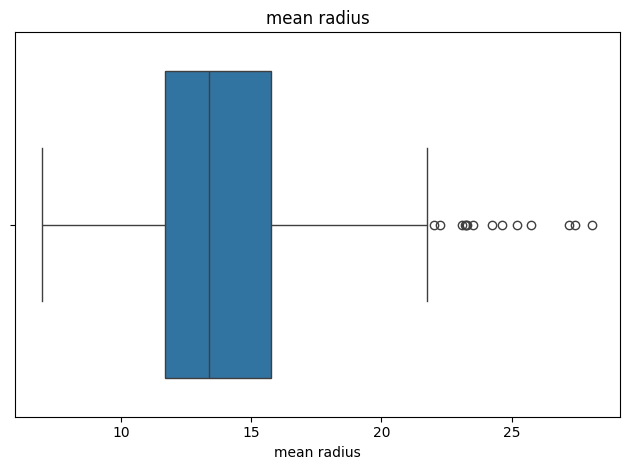

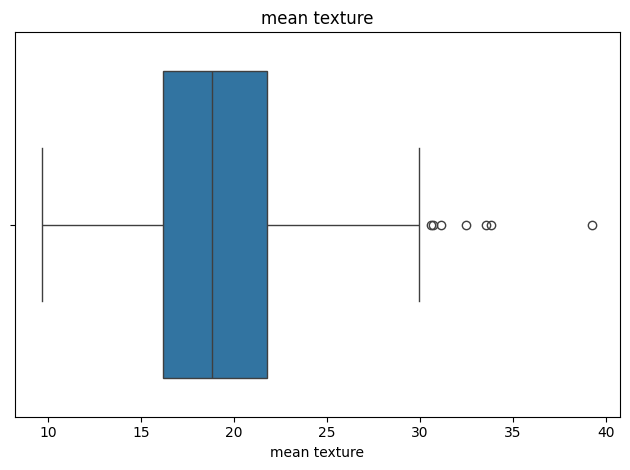

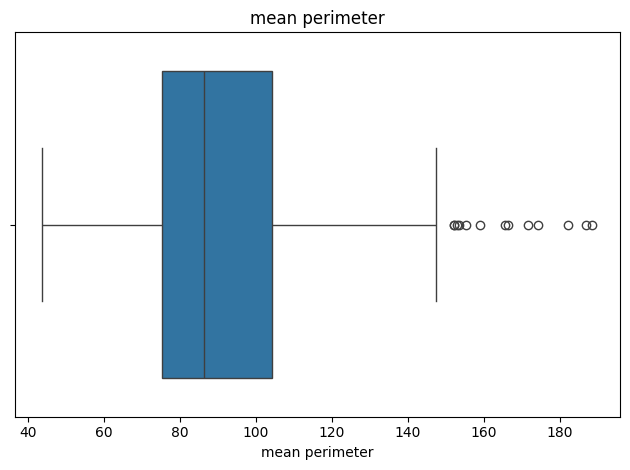

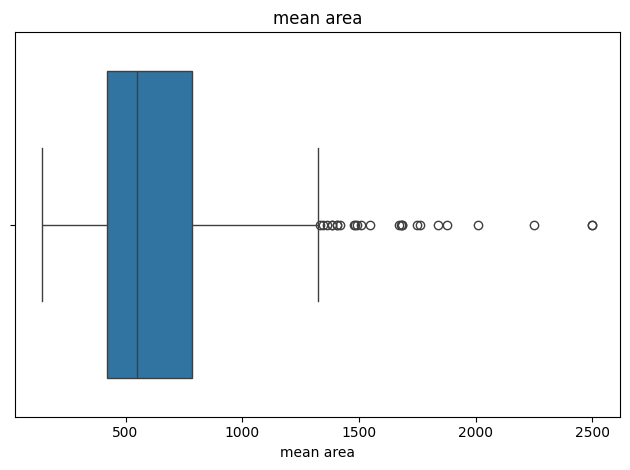

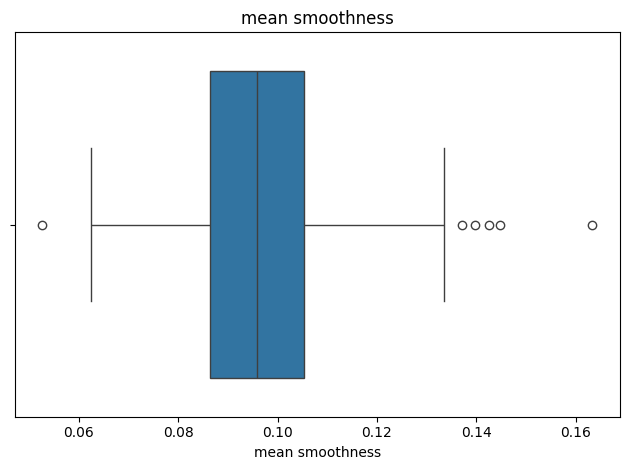

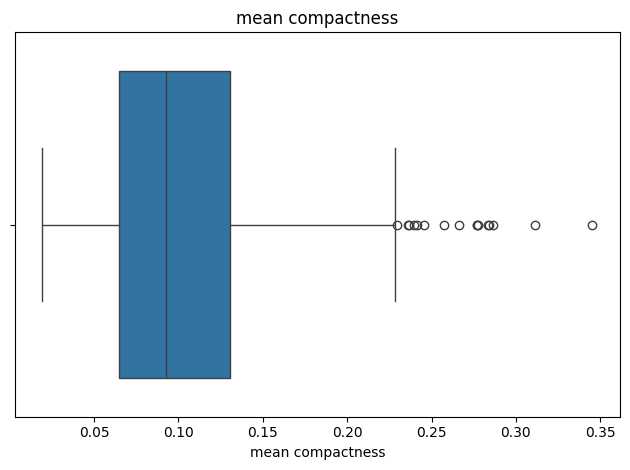

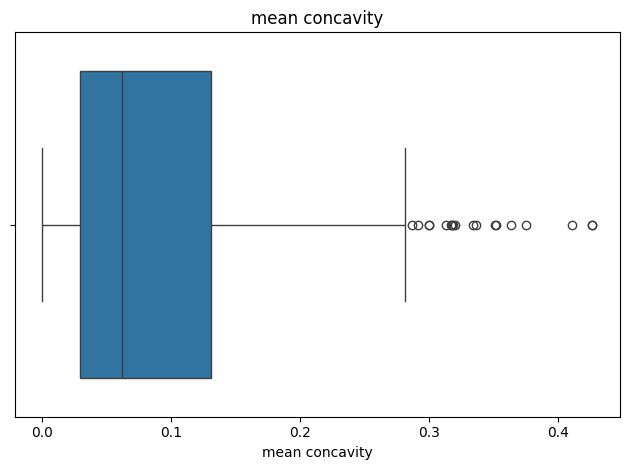

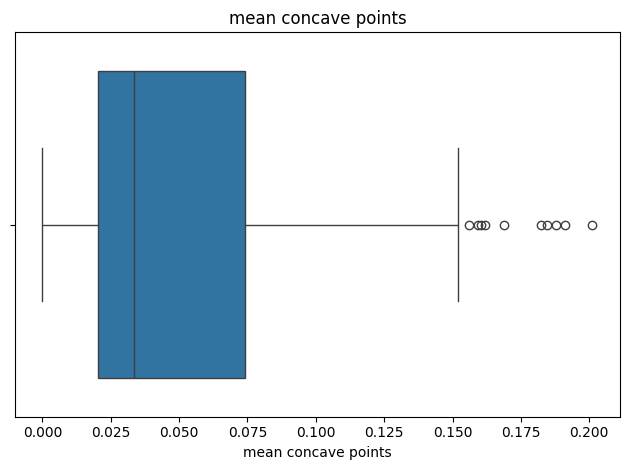

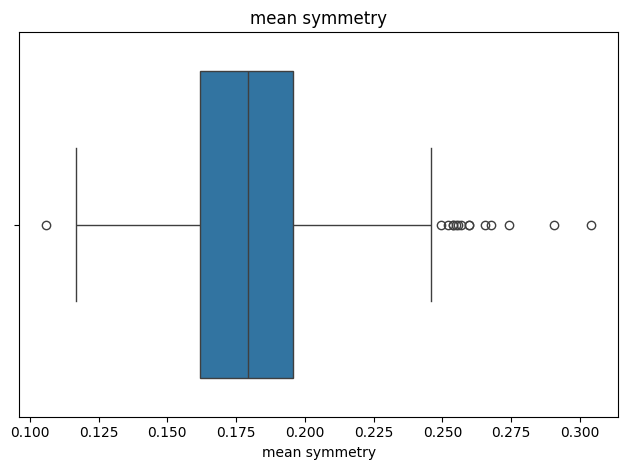

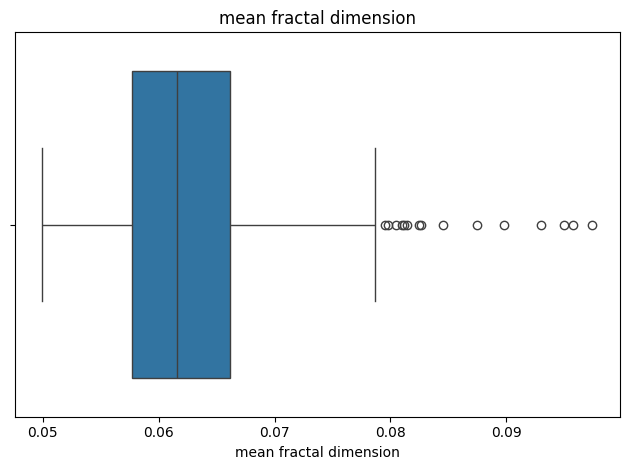

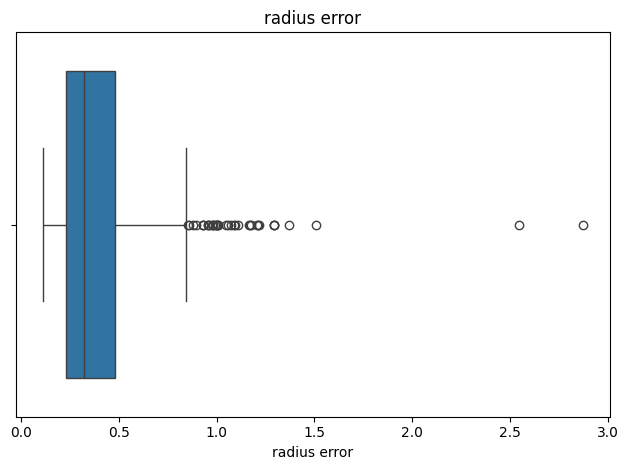

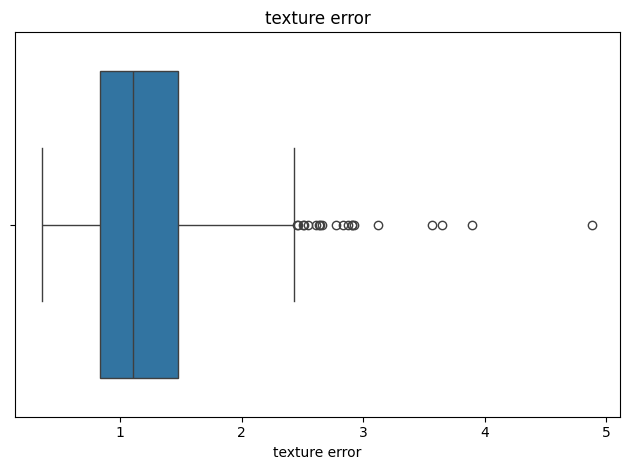

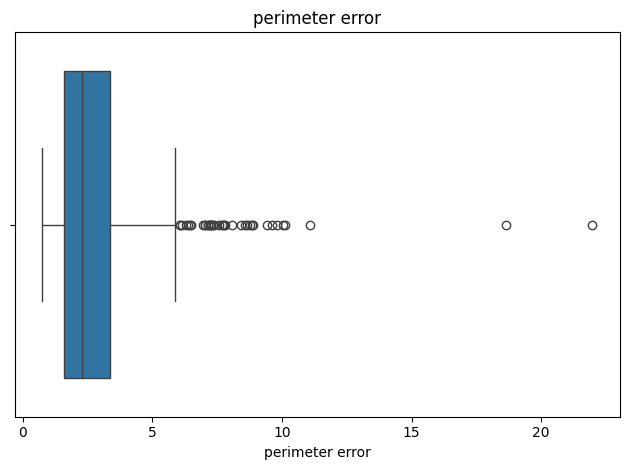

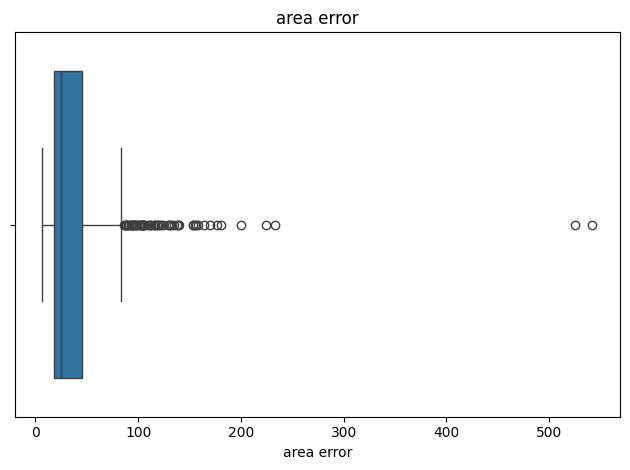

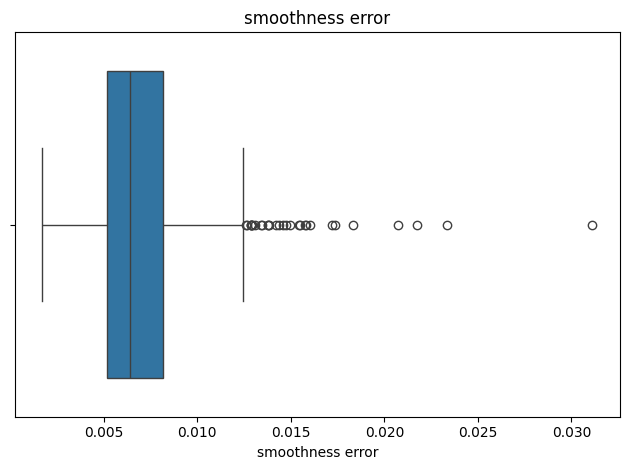

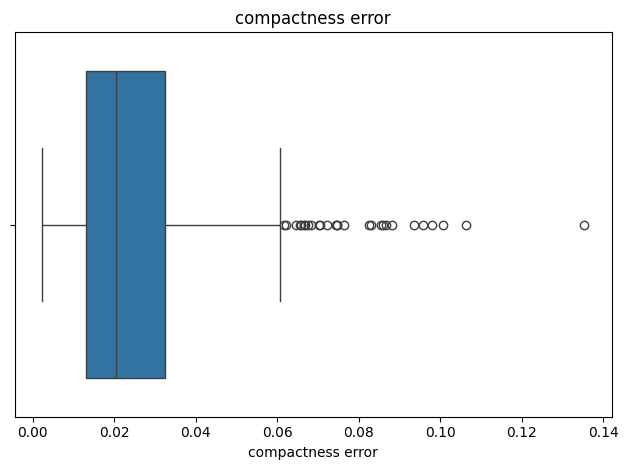

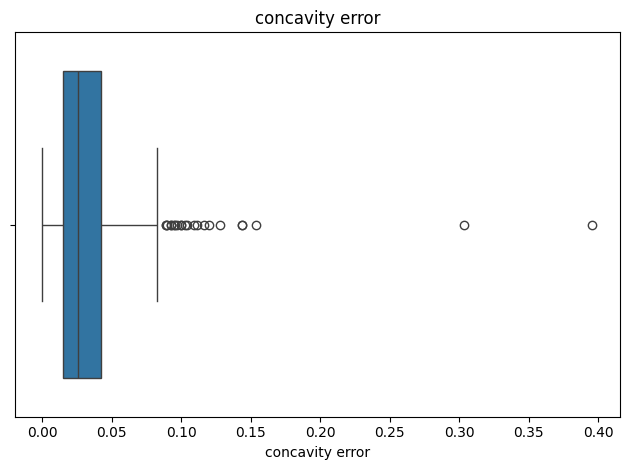

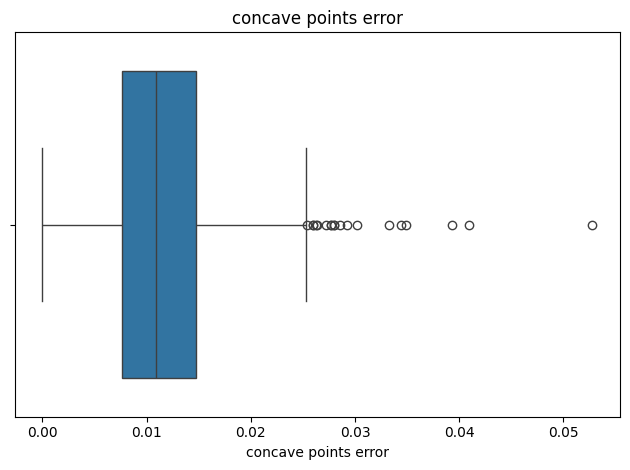

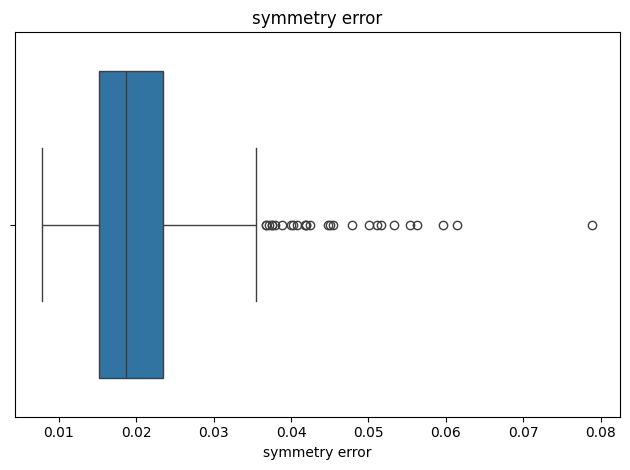

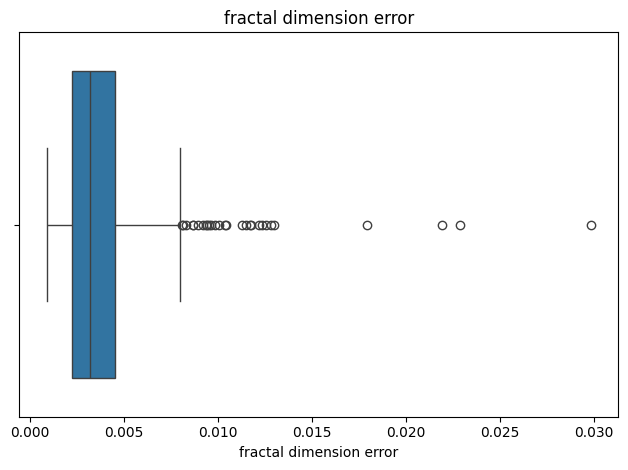

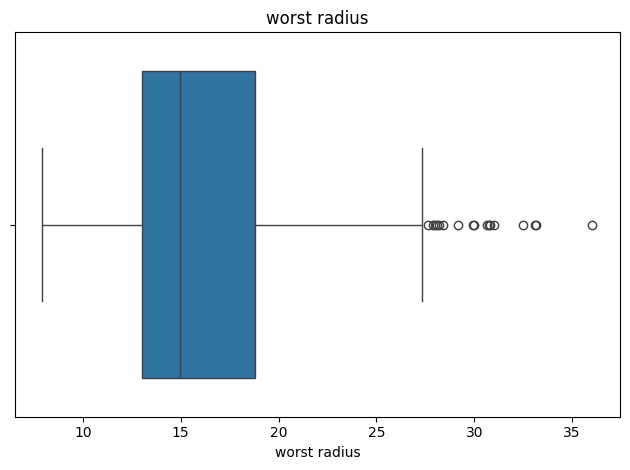

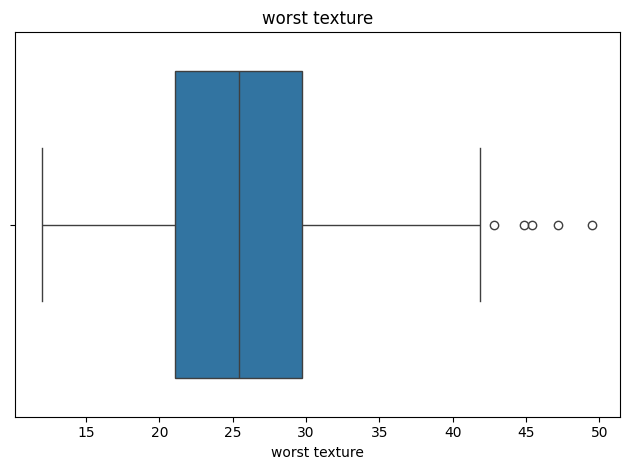

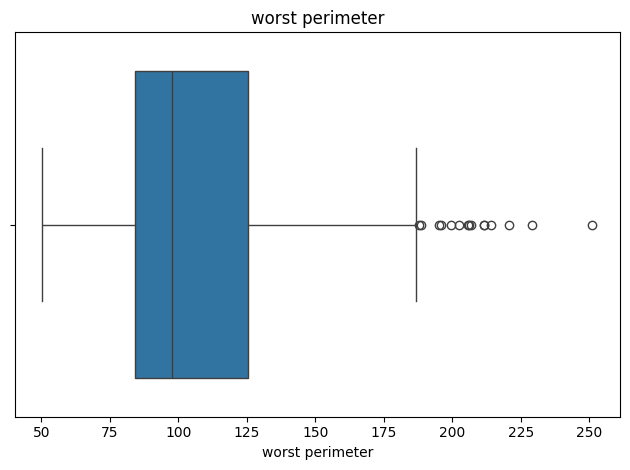

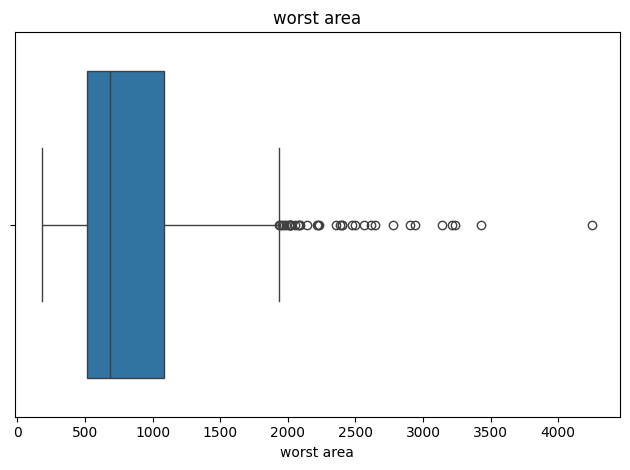

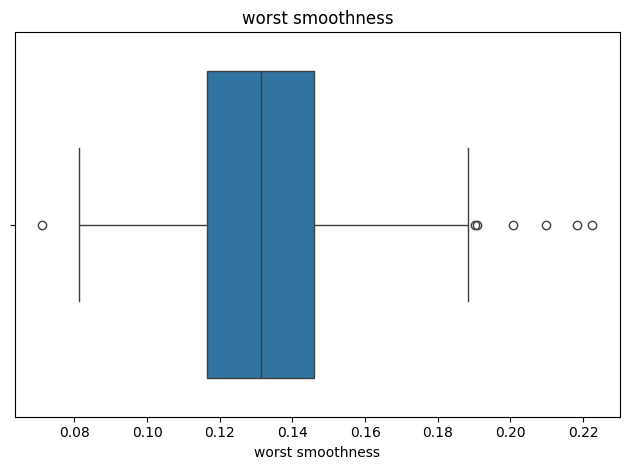

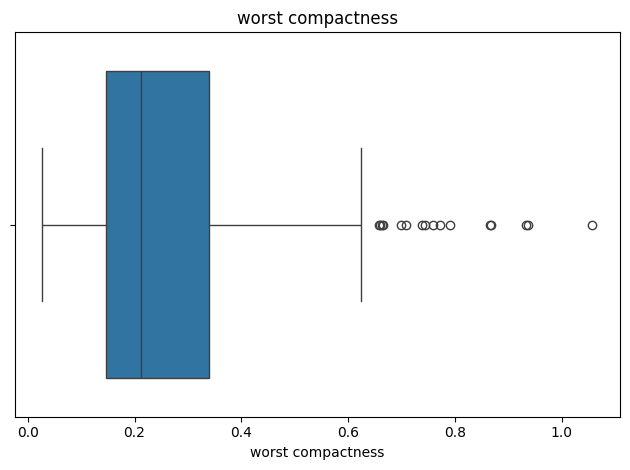

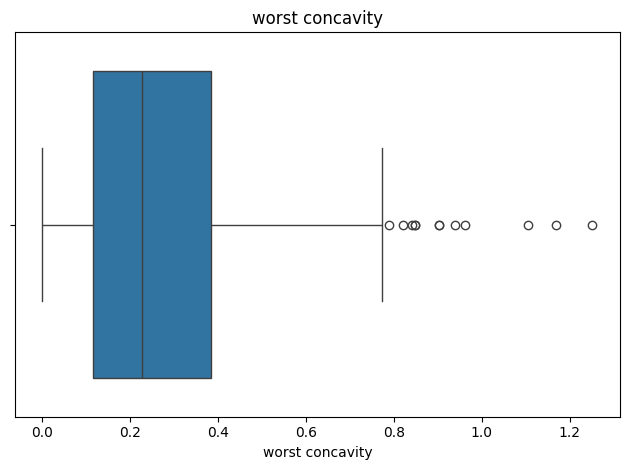

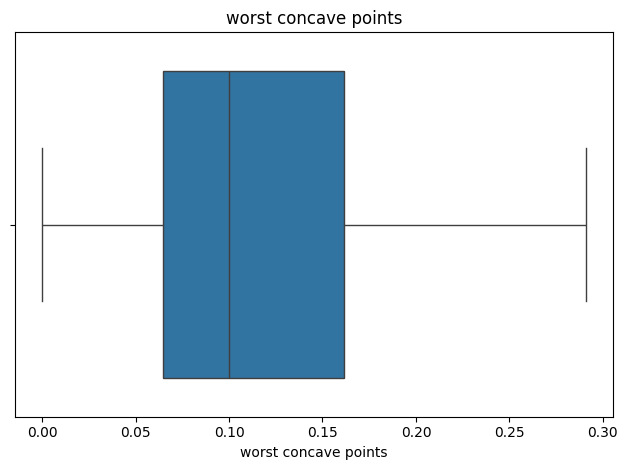

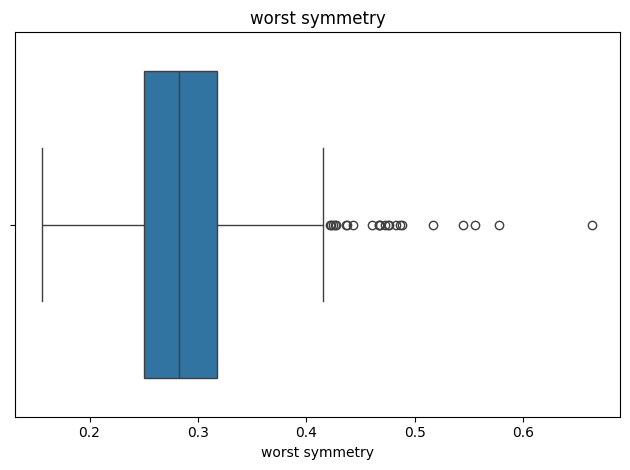

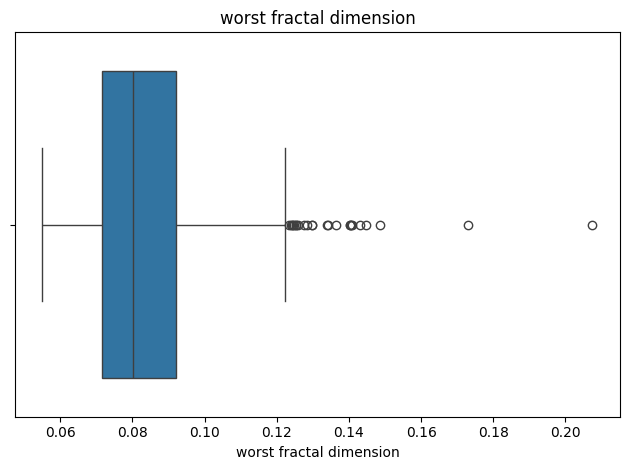

In [ ]:
for col in numeric_cols:
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.tight_layout()
    plt.show()

In [41]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

corr_cols = numeric_cols 
corr = df[corr_cols].corr().round(2)
corr

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
mean radius,1.00,0.32,1.00,0.99,0.17,0.51,0.68,0.82,0.15,-0.31,0.68,-0.10,0.67,0.74,-0.22,0.21,0.19,0.38,-0.10,-0.04,0.97,0.30,0.97,0.94,0.12,0.41,0.53,0.74,0.16,0.01,-0.73
mean texture,0.32,1.00,0.33,0.32,-0.02,0.24,0.30,0.29,0.07,-0.08,0.28,0.39,0.28,0.26,0.01,0.19,0.14,0.16,0.01,0.05,0.35,0.91,0.36,0.34,0.08,0.28,0.30,0.30,0.11,0.12,-0.42
mean perimeter,1.00,0.33,1.00,0.99,0.21,0.56,0.72,0.85,0.18,-0.26,0.69,-0.09,0.69,0.74,-0.20,0.25,0.23,0.41,-0.08,-0.01,0.97,0.30,0.97,0.94,0.15,0.46,0.56,0.77,0.19,0.05,-0.74
mean area,0.99,0.32,0.99,1.00,0.18,0.50,0.69,0.82,0.15,-0.28,0.73,-0.07,0.73,0.80,-0.17,0.21,0.21,0.37,-0.07,-0.02,0.96,0.29,0.96,0.96,0.12,0.39,0.51,0.72,0.14,0.00,-0.71
mean smoothness,0.17,-0.02,0.21,0.18,1.00,0.66,0.52,0.55,0.56,0.58,0.30,0.07,0.30,0.25,0.33,0.32,0.25,0.38,0.20,0.28,0.21,0.04,0.24,0.21,0.81,0.47,0.43,0.50,0.39,0.50,-0.36
mean compactness,0.51,0.24,0.56,0.50,0.66,1.00,0.88,0.83,0.60,0.57,0.50,0.05,0.55,0.46,0.14,0.74,0.57,0.64,0.23,0.51,0.54,0.25,0.59,0.51,0.57,0.87,0.82,0.82,0.51,0.69,-0.60
mean concavity,0.68,0.30,0.72,0.69,0.52,0.88,1.00,0.92,0.50,0.34,0.63,0.08,0.66,0.62,0.10,0.67,0.69,0.68,0.18,0.45,0.69,0.30,0.73,0.68,0.45,0.75,0.88,0.86,0.41,0.51,-0.70
mean concave points,0.82,0.29,0.85,0.82,0.55,0.83,0.92,1.00,0.46,0.17,0.70,0.02,0.71,0.69,0.03,0.49,0.44,0.62,0.10,0.26,0.83,0.29,0.86,0.81,0.45,0.67,0.75,0.91,0.38,0.37,-0.78
mean symmetry,0.15,0.07,0.18,0.15,0.56,0.60,0.50,0.46,1.00,0.48,0.30,0.13,0.31,0.22,0.19,0.42,0.34,0.39,0.45,0.33,0.19,0.09,0.22,0.18,0.43,0.47,0.43,0.43,0.70,0.44,-0.33
mean fractal dimension,-0.31,-0.08,-0.26,-0.28,0.58,0.57,0.34,0.17,0.48,1.00,0.00,0.16,0.04,-0.09,0.40,0.56,0.45,0.34,0.35,0.69,-0.25,-0.05,-0.21,-0.23,0.50,0.46,0.35,0.18,0.33,0.77,0.01


### EDA Summary — What will guide later preprocessing?

The EDA provides evidence that will guide our preprocessing decisions:

- The numerical features have different distributions and levels of skewness.
- Several features are strongly right-skewed, especially some `error` and `worst` measurements.
- Features with approximately symmetric distributions may be suitable for standard scaling.
- Strongly skewed features may require more robust preprocessing methods.
- Boxplots show potential outliers in several numerical features.
- These extreme values will not be removed automatically because they may represent valid medical observations.
- The dataset contains no missing values after inspection.
- The target variable is binary and represents the classification outcome.
- The target distribution should be considered when evaluating possible class imbalance.
- The numerical features are measured on different scales, so scaling will be important for models such as KNN, SVM, and Logistic Regression.


# 4. Define X and y

In [42]:
x = df.drop(columns=["target"])
y = df["target"]

print("Features shape:", x.shape)
print("Target shape:", y.shape)

Features shape: (569, 30)
Target shape: (569,)


## 5. Train / Test split

In [45]:
x_train, x_test, y_train, y_test = train_test_split( 
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
    )


print("Train:", x_train.shape)
print("Test :", x_test.shape)

print("\nTrain class %:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTest class %:")
print((y_test.value_counts(normalize=True) * 100).round(2))


Train: (455, 30)
Test : (114, 30)

Train class %:
target
1    62.64
0    37.36
Name: proportion, dtype: float64

Test class %:
target
1    63.16
0    36.84
Name: proportion, dtype: float64


# 6. Missing values — inspect Training Data first

Before filling anything, check the amount and type of missing data in Training Data.

In [48]:
x_train.head(5)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
546,10.32,16.35,65.31,324.9,0.09434,0.04994,0.01012,0.005495,0.1885,0.06201,0.2104,0.9670,1.356,12.97,0.007086,0.007247,0.01012,0.005495,0.01560,0.002606,11.25,21.77,71.12,384.9,0.1285,0.08842,0.04384,0.02381,0.2681,0.07399
432,20.18,19.54,133.80,1250.0,0.11330,0.14890,0.21330,0.125900,0.1724,0.06053,0.4331,1.0010,3.008,52.49,0.009087,0.027150,0.05546,0.019100,0.02451,0.004005,22.03,25.07,146.00,1479.0,0.1665,0.29420,0.53080,0.21730,0.3032,0.08075
174,10.66,15.15,67.49,349.6,0.08792,0.04302,0.00000,0.000000,0.1928,0.05975,0.3309,1.9250,2.155,21.98,0.008713,0.010170,0.00000,0.000000,0.03265,0.001002,11.54,19.20,73.20,408.3,0.1076,0.06791,0.00000,0.00000,0.2710,0.06164
221,13.56,13.90,88.59,561.3,0.10510,0.11920,0.07860,0.044510,0.1962,0.06303,0.2569,0.4981,2.011,21.03,0.005851,0.023140,0.02544,0.008360,0.01842,0.002918,14.98,17.13,101.10,686.6,0.1376,0.26980,0.25770,0.09090,0.3065,0.08177
289,11.37,18.89,72.17,396.0,0.08713,0.05008,0.02399,0.021730,0.2013,0.05955,0.2656,1.9740,1.954,17.49,0.006538,0.013950,0.01376,0.009924,0.03416,0.002928,12.36,26.14,79.29,459.3,0.1118,0.09708,0.07529,0.06203,0.3267,0.06994


In [49]:
missing_train = x_train.isna().sum().to_frame("Missing_Count")

missing_train["Missing_%"] = (x_train.isna().mean() * 100).round(2)

missing_train["Data_Type"] = x_train.dtypes.astype(str)

missing_train.sort_values("Missing_%", ascending=False)


,Missing_Count,Missing_%,Data_Type
mean radius,0,0.0,float64
mean texture,0,0.0,float64
mean perimeter,0,0.0,float64
mean area,0,0.0,float64
mean smoothness,0,0.0,float64
mean compactness,0,0.0,float64
mean concavity,0,0.0,float64
mean concave points,0,0.0,float64
mean symmetry,0,0.0,float64
mean fractal dimension,0,0.0,float64


# 7. Outliers — diagnose every numerical feature

In [50]:
# Outlier analysis on training data only

numeric_check_cols = x_train.columns

for col in numeric_check_cols:
    data = x_train[col]

    # IQR method
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    iqr_outliers = ((data < lower) | (data > upper)).sum()

    # Z-score method
    z = ((data - data.mean()) / data.std()).abs()
    z_outliers = (z > 3).sum()

    print("\n", col)
    print("Skewness:", round(data.skew(), 3))
    print("IQR outliers:", iqr_outliers)
    print("Z > 3:", z_outliers)
    print("Min:", round(data.min(), 2))
    print("Max:", round(data.max(), 2))


 mean radius
Skewness: 0.917
IQR outliers: 12
Z > 3: 4
Min: 6.98
Max: 28.11

 mean texture
Skewness: 0.723
IQR outliers: 7
Z > 3: 4
Min: 9.71
Max: 39.28

 mean perimeter
Skewness: 0.967
IQR outliers: 13
Z > 3: 5
Min: 43.79
Max: 188.5

 mean area
Skewness: 1.539
IQR outliers: 24
Z > 3: 8
Min: 143.5
Max: 2499.0

 mean smoothness
Skewness: 0.396
IQR outliers: 5
Z > 3: 4
Min: 0.06
Max: 0.14

 mean compactness
Skewness: 1.251
IQR outliers: 14
Z > 3: 8
Min: 0.02
Max: 0.35

 mean concavity
Skewness: 1.385
IQR outliers: 15
Z > 3: 6
Min: 0.0
Max: 0.43

 mean concave points
Skewness: 1.181
IQR outliers: 8
Z > 3: 4
Min: 0.0
Max: 0.2

 mean symmetry
Skewness: 0.773
IQR outliers: 14
Z > 3: 5
Min: 0.11
Max: 0.3

 mean fractal dimension
Skewness: 1.31
IQR outliers: 13
Z > 3: 6
Min: 0.05
Max: 0.1

 radius error
Skewness: 2.966
IQR outliers: 37
Z > 3: 8
Min: 0.11
Max: 2.87

 texture error
Skewness: 1.749
IQR outliers: 18
Z > 3: 5
Min: 0.36
Max: 4.88

 perimeter error
Skewness: 3.371
IQR outliers: 33
Z

## 8. Feature Scaling

In [51]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

### 8.1 Verify Scaling

In [52]:
print("Mean:", x_train_scaled.mean(axis=0).round(2))
print("Std:", x_train_scaled.std(axis=0).round(2))

Mean: [-0.  0. -0. -0.  0. -0. -0.  0. -0.  0. -0. -0.  0.  0. -0. -0.  0. -0.
  0.  0.  0. -0. -0.  0.  0. -0.  0. -0. -0.  0.]
Std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]


## 9. Baseline Model — Logistic Regression

In [53]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)

model.fit(x_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [54]:
y_pred = model.predict(x_test_scaled)

print("Predictions:", y_pred[:10])

Predictions: [0 1 0 1 0 1 1 0 0 0]


## 10. Model Evaluation

In [55]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

Accuracy : 0.9825
Precision: 0.9861
Recall   : 0.9861
F1-Score : 0.9861


### 10.1 Classification Report

In [56]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=dataset.target_names
))

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



### 10.2 Confusion Matrix

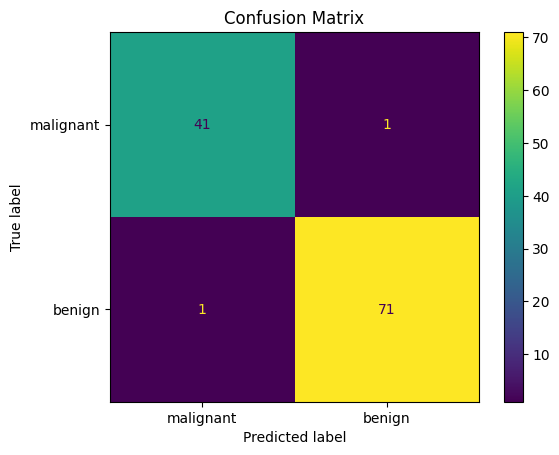

In [57]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dataset.target_names
)

disp.plot()

plt.title("Confusion Matrix")
plt.show()

## 11. Sample Prediction

In [61]:
sample = x_test_scaled[0].reshape(1, -1)

sample_prediction = model.predict(sample)[0]

print("Predicted class:", sample_prediction)
print("Predicted label:", dataset.target_names[sample_prediction])

actual_class = y_test.iloc[0]

print("Actual class:", actual_class)
print("Actual label:", dataset.target_names[actual_class])

Predicted class: 0
Predicted label: malignant
Actual class: 0
Actual label: malignant
